In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread("peppers.png")

(np.float64(-0.5), np.float64(511.5), np.float64(383.5), np.float64(-0.5))

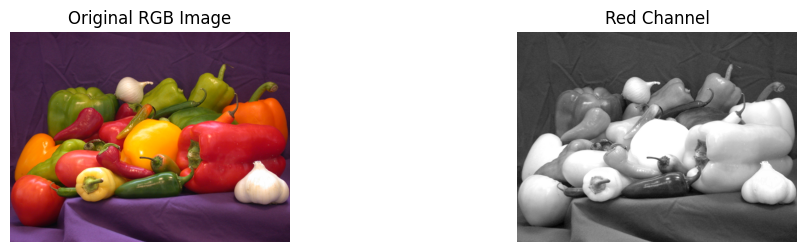

In [ ]:

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

b, g, r = cv2.split(img)

plt.figure(figsize=(12, 6))
plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title('Original RGB Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(r, cmap='gray')
plt.title('Red Channel')
plt.axis('off')

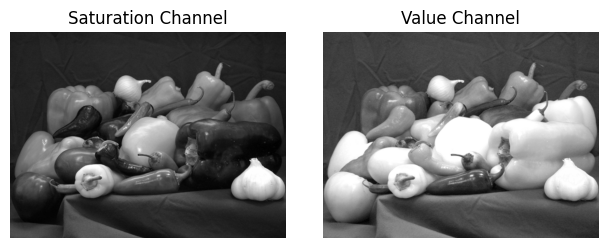

In [9]:

# Saturation Channel
plt.subplot(2, 2, 3)
plt.imshow(g, cmap='gray')
plt.title('Saturation Channel')
plt.axis('off')

# Value Channel
plt.subplot(2, 2, 4)
plt.imshow(r, cmap='gray')
plt.title('Value Channel')
plt.axis('off')

plt.tight_layout()
plt.show()

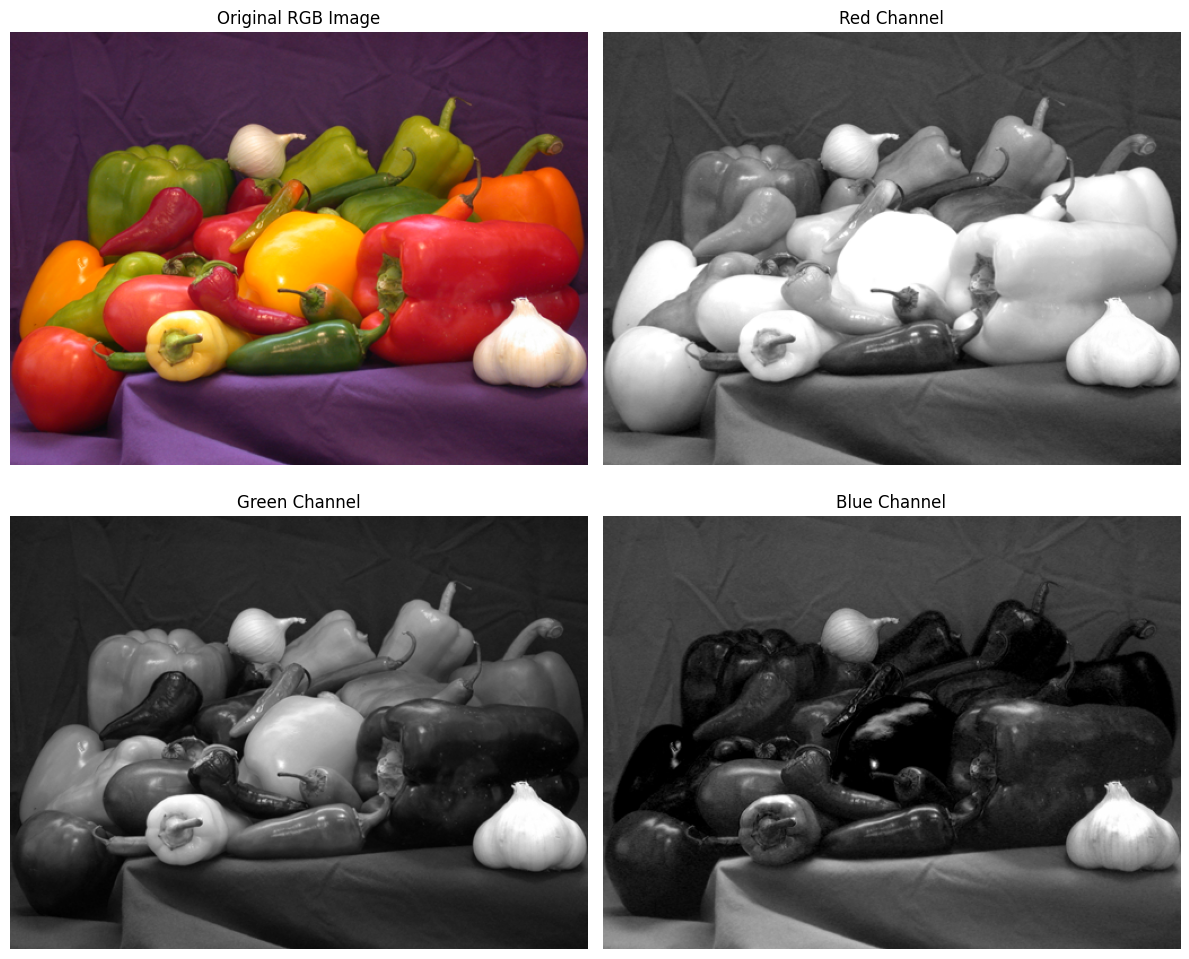

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('peppers.png')

if img is None:
    raise FileNotFoundError("Image not found at /content/peppers.png. Please upload or download it first!")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

b, g, r = cv2.split(img)

plt.figure(figsize=(12, 10))

# 1. Original RGB image
plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title('Original RGB Image')
plt.axis('off')

# 2. Red Channel
plt.subplot(2, 2, 2)
plt.imshow(r, cmap='gray')
plt.title('Red Channel')
plt.axis('off')

# 3. Green Channel
plt.subplot(2, 2, 3)
plt.imshow(g, cmap='gray')
plt.title('Green Channel')
plt.axis('off')

# 4. Blue Channel
plt.subplot(2, 2, 4)
plt.imshow(b, cmap='gray')
plt.title('Blue Channel')
plt.axis('off')

plt.tight_layout()
plt.show()


'wget' is not recognized as an internal or external command,
operable program or batch file.


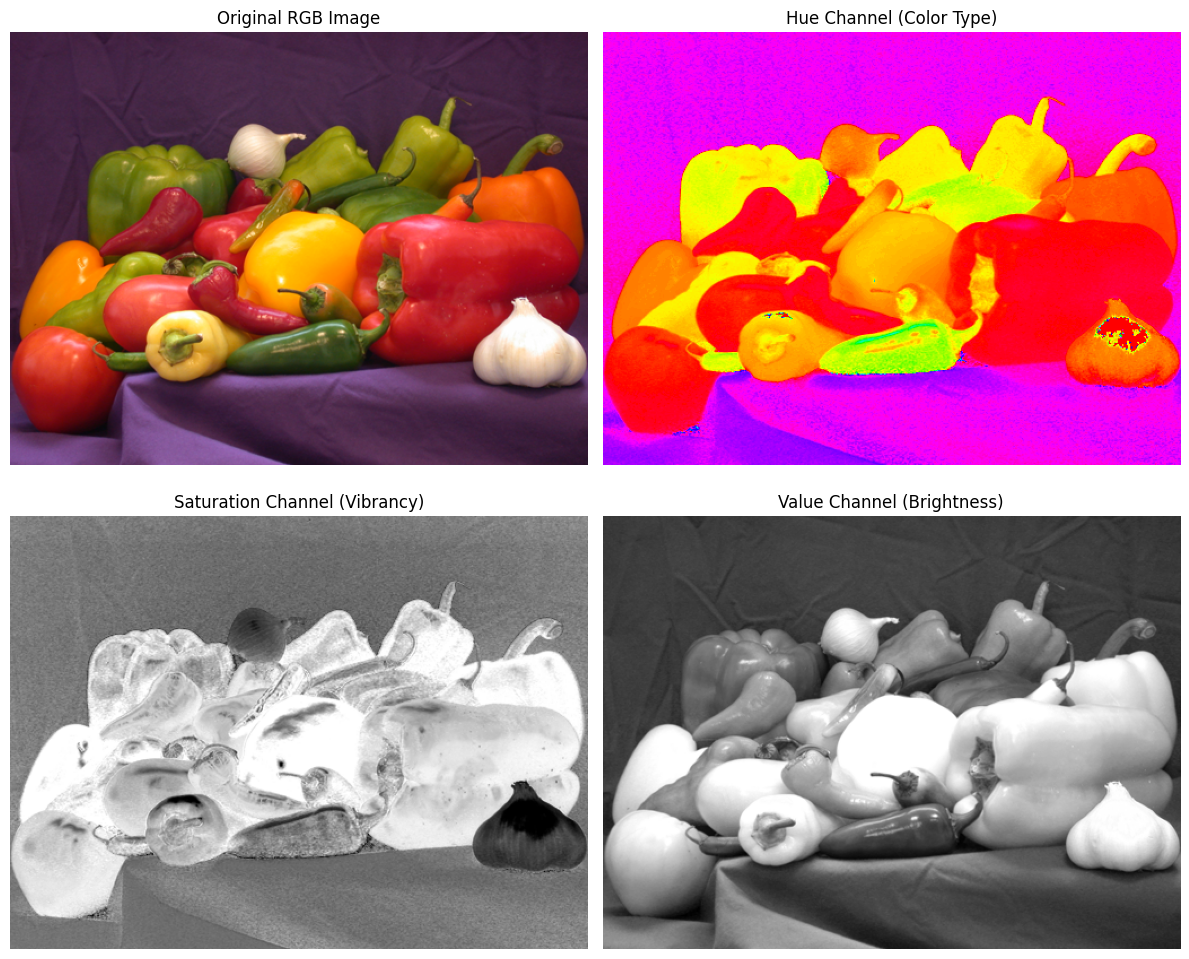

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('peppers.png')

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(img_hsv)

plt.figure(figsize=(12, 10))

# Original RGB Image
plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title('Original RGB Image')
plt.axis('off')

# Hue Channel (often plotted with a colormap like 'hsv' to see the actual color wheel representation)
plt.subplot(2, 2, 2)
plt.imshow(h, cmap='hsv')
plt.title('Hue Channel (Color Type)')
plt.axis('off')

# Saturation Channel
plt.subplot(2, 2, 3)
plt.imshow(s, cmap='gray')
plt.title('Saturation Channel (Vibrancy)')
plt.axis('off')

# Value Channel
plt.subplot(2, 2, 4)
plt.imshow(v, cmap='gray')
plt.title('Value Channel (Brightness)')
plt.axis('off')

plt.tight_layout()
plt.show()


In [14]:
!wget -q -O /content/peppers.png https://githubusercontent.com

'wget' is not recognized as an internal or external command,
operable program or batch file.


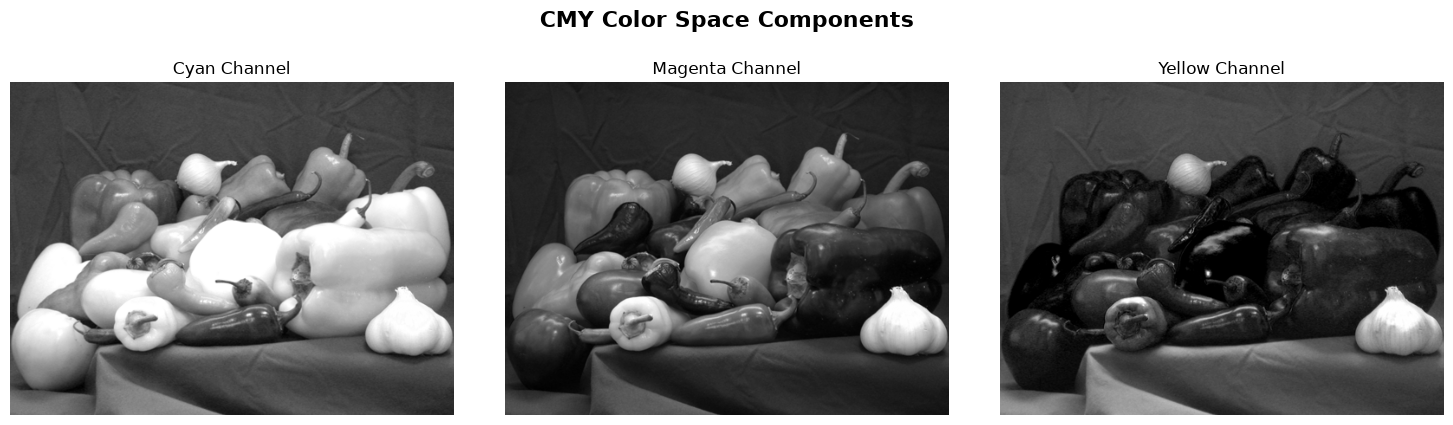

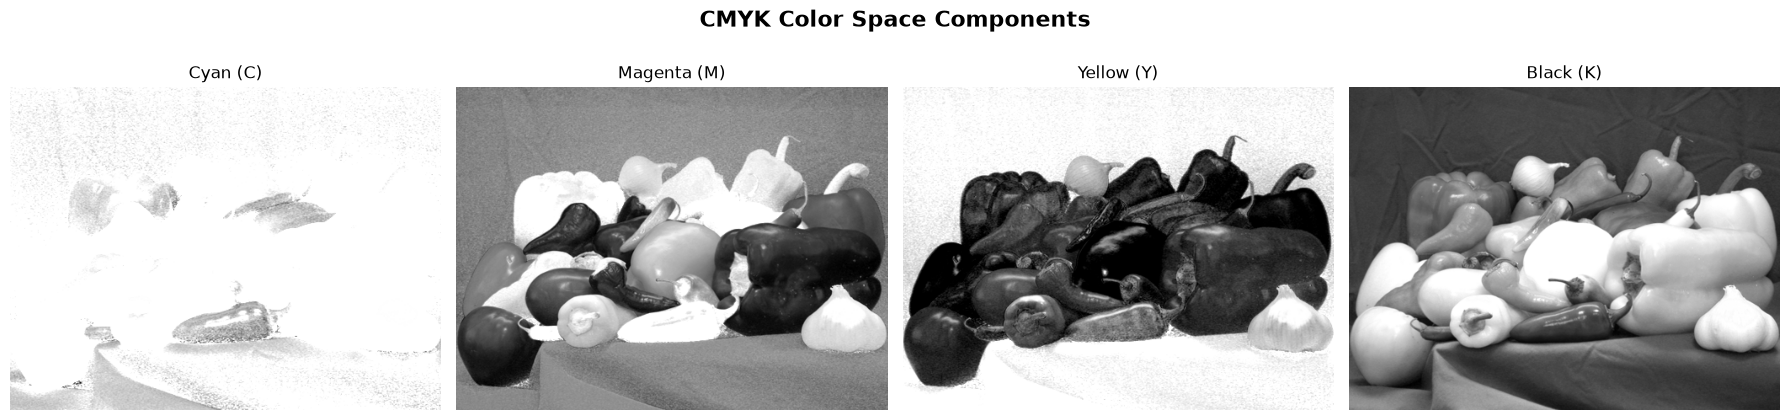

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('peppers.png')

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_normalized = img_rgb / 255.0

r, g, b = img_normalized[:,:,0], img_normalized[:,:,1], img_normalized[:,:,2]

c_cmy = 1.0 - r
m_cmy = 1.0 - g
y_cmy = 1.0 - b


k = np.min(np.stack([c_cmy, m_cmy, y_cmy], axis=-1), axis=-1)

k_mask = (k == 1.0)
c_cmyk = np.where(k_mask, 0, (c_cmy - k) / (1.0 - k))
m_cmyk = np.where(k_mask, 0, (m_cmy - k) / (1.0 - k))
y_cmyk = np.where(k_mask, 0, (y_cmy - k) / (1.0 - k))


# --- PLOT 1: CMY Visualization ---
plt.figure(figsize=(15, 4))
plt.suptitle('CMY Color Space Components', fontsize=16, weight='bold', y=1.05)

titles_cmy = ['Cyan Channel', 'Magenta Channel', 'Yellow Channel']
channels_cmy = [c_cmy, m_cmy, y_cmy]
cmaps_cmy = ['Cyan', 'Magenta', 'Yellow'] # Custom conceptual label for understanding

for i in range(3):
    plt.subplot(1, 3, i+1)

    plt.imshow(channels_cmy[i], cmap='gray_r') 
    plt.title(titles_cmy[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

# --- PLOT 2: CMYK Visualization ---
plt.figure(figsize=(18, 4))
plt.suptitle('CMYK Color Space Components', fontsize=16, weight='bold', y=1.05)

titles_cmyk = ['Cyan (C)', 'Magenta (M)', 'Yellow (Y)', 'Black (K)']
channels_cmyk = [c_cmyk, m_cmyk, y_cmyk, k]

for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(channels_cmyk[i], cmap='gray_r')
    plt.title(titles_cmyk[i])
    plt.axis('off')
plt.tight_layout()
plt.show()


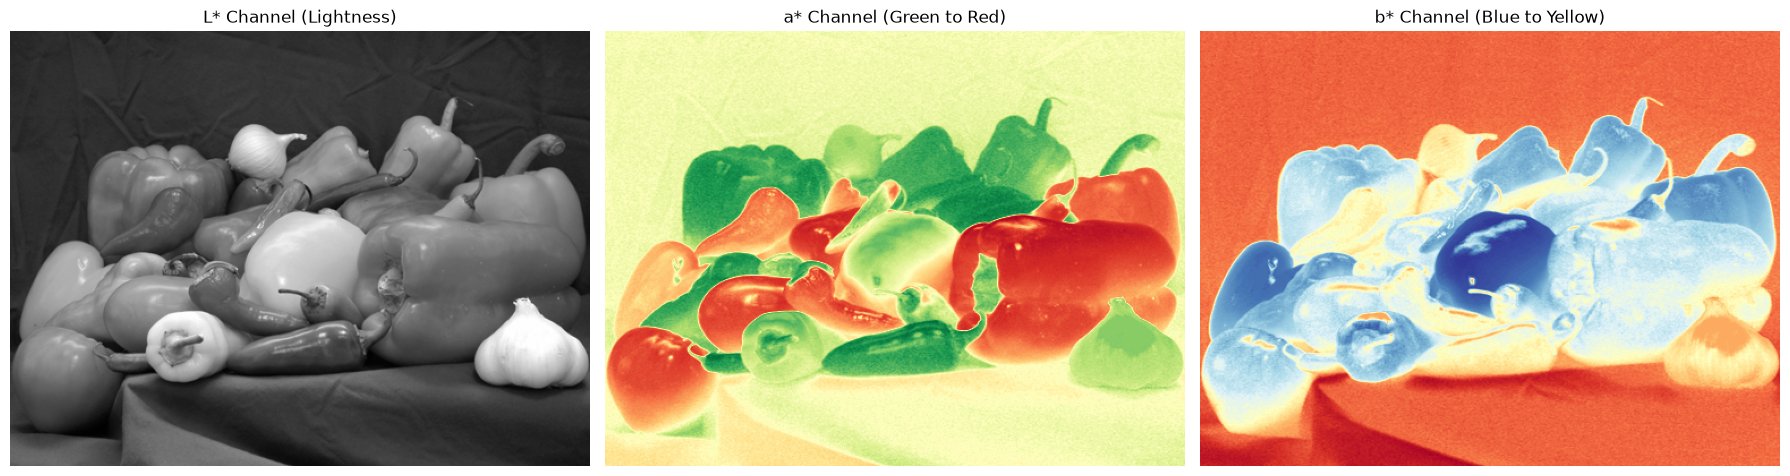

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('peppers.png')

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
lab_image_cv2 = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)

l_channel = lab_image_cv2[:,:,0]
a_channel = lab_image_cv2[:,:,1]
b_channel = lab_image_cv2[:,:,2]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# L* Channel (Lightness)
axes[0].imshow(l_channel, cmap='gray')
axes[0].set_title('L* Channel (Lightness)')
axes[0].axis('off')

# a* Channel (Green to Red spectrum)
axes[1].imshow(a_channel, cmap='RdYlGn_r')
axes[1].set_title('a* Channel (Green to Red)')
axes[1].axis('off')

# b* Channel (Blue to Yellow spectrum)
axes[2].imshow(b_channel, cmap='RdYlBu')
axes[2].set_title('b* Channel (Blue to Yellow)')
axes[2].axis('off')

plt.tight_layout()
plt.show()
